In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder,OrdinalEncoder,OneHotEncoder
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split,cross_val_score,validation_curve,GridSearchCV,LeaveOneOut
from sklearn.metrics import mean_absolute_error, r2_score
%matplotlib


Using matplotlib backend: module://matplotlib_inline.backend_inline


In [2]:
# !pip install openpyxl

In [3]:
data=pd.read_excel("data2.xlsx")

In [4]:
data.head()

,start,end,Acceptez-vous de participer à cette enquête anonyme ?,Quelle est votre promotion ?,Quelle est votre tranche d'âge ?,Combien d'heures de cours suivez-vous par semaine ?,"Combien d'heures par semaine consacrez-vous à l'étude personnelle, hors cours ?",Où étudiez-vous le plus souvent ?,"Où étudiez-vous le plus souvent ?/domicile,",Où étudiez-vous le plus souvent ?/bibliothèque,...,Un commentaire à ajouter ? (facultatif),_id,_uuid,_submission_time,_validation_status,_status,_submitted_by,__version__,meta/rootUuid,_index
0,2026-11-02 22:09:11.286,2026-11-02 22:11:23.040,NaN,L3,18-20,10h,je n'étudie pas pendant la semaine.,"domicile,",1.0,0.0,...,NaN,906614785,73ba0a0f-a1d9-44aa-8086-fd8d23c9e9dd,2026-11-02 21:11:24,NaN,submitted_via_web,NaN,vdRjbomor52Cg3oeR2XVBn,uuid:73ba0a0f-a1d9-44aa-8086-fd8d23c9e9dd,1
1,2026-11-02 22:10:24.687,2026-11-02 22:12:40.623,NaN,L3,18-20,40h,5-10h,"domicile, bibliothèque salle de cours",1.0,1.0,...,Je suis très indiscipliné,906615200,8b22e6cc-f677-426f-ab1d-8050f591b8e9,2026-11-02 21:12:42,NaN,submitted_via_web,NaN,vdRjbomor52Cg3oeR2XVBn,uuid:8b22e6cc-f677-426f-ab1d-8050f591b8e9,2
2,2026-11-02 22:08:58.180,2026-11-02 22:12:43.822,NaN,L2,18-20,40h,11-20h,"domicile, bibliothèque",1.0,1.0,...,Questions insuffisantes,906615221,c633b24e-73b0-43da-b85a-87258f4c1136,2026-11-02 21:12:45,NaN,submitted_via_web,NaN,vdRjbomor52Cg3oeR2XVBn,uuid:c633b24e-73b0-43da-b85a-87258f4c1136,3
3,2026-11-02 22:11:41.963,2026-11-02 22:12:52.961,NaN,L3,18-20,40h,2-4h,"domicile,",1.0,0.0,...,NaN,906615275,a14da522-c822-4e55-bfa2-0db007afd7a8,2026-11-02 21:12:56,NaN,submitted_via_web,NaN,vdRjbomor52Cg3oeR2XVBn,uuid:a14da522-c822-4e55-bfa2-0db007afd7a8,4
4,2026-11-02 22:19:34.490,2026-11-02 22:20:24.775,NaN,L2,18-20,60h,2-4h,"domicile, bibliothèque salle de cours",1.0,1.0,...,NaN,906616793,b787a9b0-cf74-4e09-bbf4-9cd4c486b4c5,2026-11-02 21:20:25,NaN,submitted_via_web,NaN,vdRjbomor52Cg3oeR2XVBn,uuid:b787a9b0-cf74-4e09-bbf4-9cd4c486b4c5,5


In [5]:
data.shape

(93, 38)

In [6]:
data.columns

Index(['start', 'end', 'Acceptez-vous de participer à cette enquête anonyme ?',
       'Quelle est votre promotion ? ', 'Quelle est votre tranche d'âge ?',
       'Combien d'heures de cours suivez-vous par semaine ?',
       'Combien d'heures par semaine consacrez-vous à l'étude personnelle, hors cours ?',
       'Où étudiez-vous le plus souvent ?',
       'Où étudiez-vous le plus souvent ?/domicile,',
       'Où étudiez-vous le plus souvent ?/bibliothèque',
       'Où étudiez-vous le plus souvent ?/salle de cours',
       'Où étudiez-vous le plus souvent ?/cybercafé',
       'Où étudiez-vous le plus souvent ?/chez un ami, autre',
       'Où étudiez-vous le plus souvent ?/Autre lieu ',
       'Enregistrez le point du lieu d'étude (uniquement hors domicile)',
       '_Enregistrez le point du lieu d'étude (uniquement hors domicile)_latitude',
       '_Enregistrez le point du lieu d'étude (uniquement hors domicile)_longitude',
       '_Enregistrez le point du lieu d'étude (uniquement hors

# colonnes a nettoyer

In [7]:
colonnes_techniques = ["_status", "_validation_status", "_submitted_by",
                       "__version__", "meta/rootUuid", "_index", "_uuid", "_id"]

data = data.drop(columns=[c for c in colonnes_techniques if c in data.columns])
print(data.shape)

(93, 30)


In [8]:
data.shape

(93, 30)

In [9]:
# 1. Consentement
c_consent = [c for c in data.columns if "Acceptez" in c][0]
cons = data[c_consent].astype(str).str.strip().str.lower()

# Premier « oui » : on garde les vides antérieurs (collecte avant l'ajout du champ),
# on retire le « non » et les vides postérieurs
premier_oui = data.loc[cons == "oui", "_submission_time"].min()
vides_anciens = data[c_consent].isna() & (data["_submission_time"] < premier_oui)

n0 = len(data)
data = data[(cons == "oui") | vides_anciens].copy()
print("Lignes retirées (consentement refusé ou manquant) :", n0 - len(data))
print("Lignes restantes :", len(data))

# 2. Durée de remplissage : on regarde d'abord, on décide ensuite
data["duree_sec"] = (data["end"] - data["start"]).dt.total_seconds()
print("Réponses de moins de 60 secondes :")
print(data.loc[data["duree_sec"] < 60, ["_submission_time", "duree_sec"]])



Lignes retirées (consentement refusé ou manquant) : 2
Lignes restantes : 91
Réponses de moins de 60 secondes :
      _submission_time  duree_sec
4  2026-11-02 21:20:25     50.285
6  2026-11-02 21:23:06     43.666
11 2026-11-02 21:52:43     58.350
12 2026-11-02 21:53:08     35.621
16 2026-11-03 02:53:35     27.696
23 2026-11-03 06:55:12     57.705
46 2026-11-03 16:50:29     57.671
65 2026-11-03 20:57:55     41.638
89 2026-11-04 14:15:26     45.356
92 2026-11-04 19:33:39     37.951


In [10]:
data = data[data["duree_sec"] >= 60].copy()

In [11]:
data.columns

Index(['start', 'end', 'Acceptez-vous de participer à cette enquête anonyme ?',
       'Quelle est votre promotion ? ', 'Quelle est votre tranche d'âge ?',
       'Combien d'heures de cours suivez-vous par semaine ?',
       'Combien d'heures par semaine consacrez-vous à l'étude personnelle, hors cours ?',
       'Où étudiez-vous le plus souvent ?',
       'Où étudiez-vous le plus souvent ?/domicile,',
       'Où étudiez-vous le plus souvent ?/bibliothèque',
       'Où étudiez-vous le plus souvent ?/salle de cours',
       'Où étudiez-vous le plus souvent ?/cybercafé',
       'Où étudiez-vous le plus souvent ?/chez un ami, autre',
       'Où étudiez-vous le plus souvent ?/Autre lieu ',
       'Enregistrez le point du lieu d'étude (uniquement hors domicile)',
       '_Enregistrez le point du lieu d'étude (uniquement hors domicile)_latitude',
       '_Enregistrez le point du lieu d'étude (uniquement hors domicile)_longitude',
       '_Enregistrez le point du lieu d'étude (uniquement hors

In [12]:

journal = [("Données brutes", len(data))]

def trouver(mots):
    res = [c for c in data.columns if all(m in c for m in mots)]
    return res[0]

c_consent  = trouver(["Acceptez"])
c_cours    = trouver(["heures de cours"])
c_etude    = trouver(["étude personnelle"])
c_planning = trouver(["Planifiez"])
c_dom      = trouver(["Où étudiez", "/domicile"])
c_lat      = trouver(["latitude"])
c_lon      = trouver(["longitude"])
cols_lieux = [c for c in data.columns if "Où étudiez" in c and "/" in c and "domicile" not in c]
cols_dist  = [c for c in data.columns if "distractions" in c and "/" in c]

# ============================================================
# 1. Consentement (avant de supprimer _submission_time)
# ============================================================
cons = data[c_consent].astype(str).str.strip().str.lower()
premier_oui = data.loc[cons == "oui", "_submission_time"].min()
vides_anciens = data[c_consent].isna() & (data["_submission_time"] < premier_oui)
data = data[(cons == "oui") | vides_anciens].copy()
journal.append(("Après consentement (retrait du refus et des vides postérieurs)", len(data)))

# ============================================================
# 2. Durée de remplissage : retrait des réponses < 60 secondes
# ============================================================
data["duree_sec"] = (data["end"] - data["start"]).dt.total_seconds()
data = data[data["duree_sec"] >= 60].copy()
journal.append(("Après retrait des réponses < 60 secondes", len(data)))


# ============================================================
# 4. Variables du modèle
# ============================================================
# Heures de cours : "40h" -> 40
data["heures_cours_sem"] = pd.to_numeric(
    data[c_cours].astype(str).str.extract(r"(\d+)")[0], errors="coerce")

# Heures d'étude personnelle : tranches -> valeurs centrales
# (choix à justifier dans le rapport)
def conv_etude(t):
    t = str(t)
    if "pas pendant" in t: return 0
    if "plus de" in t:     return 25
    if "2-4" in t:         return 3
    if "5-10" in t:        return 7.5
    if "11-20" in t:       return 15.5
    return np.nan
data["heures_etude_perso"] = data[c_etude].apply(conv_etude)

# Planning : oui = 1, non = 0
data["planning"] = data[c_planning].astype(str).str.strip().str.lower().map({"oui": 1, "non": 0})

# Hors domicile : 1 si au moins un lieu autre que le domicile est coché
data["hors_domicile"] = (data[cols_lieux].fillna(0).sum(axis=1) > 0).astype(int)

# Nombre de distractions cochées
data["nb_distractions"] = data[cols_dist].fillna(0).sum(axis=1)

# ============================================================
# 5. GPS : retrait des coordonnées quand le domicile est coché
# ============================================================
data.loc[data[c_dom].fillna(0) == 1, [c_lat, c_lon]] = np.nan

# ============================================================
# 6. Valeurs aberrantes et manquantes
# ============================================================
# 80 h de cours par semaine est impossible : on retire ces lignes
data = data[data["heures_cours_sem"] <= 60]
journal.append(("Après retrait des heures de cours > 60", len(data)))

features = ["heures_cours_sem", "planning", "hors_domicile", "nb_distractions"]
cible = "heures_etude_perso"

data_model = data[features + [cible]].dropna()
journal.append(("Lignes complètes pour la régression", len(data_model)))

print("JOURNAL DE NETTOYAGE")
for etape, n in journal:
    print(f"  {etape} : {n}")

# ============================================================
# 7. Séparation apprentissage / test (80 % / 20 %)
# ============================================================
X = data_model[features]
y = data_model[cible]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# ============================================================
# 8. Régression linéaire
# ============================================================
modele = LinearRegression()
modele.fit(X_train, y_train)
y_pred = modele.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Référence : toujours la moyenne de l'apprentissage
y_ref = np.full(len(y_test), y_train.mean())
mae_ref = mean_absolute_error(y_test, y_ref)

print("\nRÉSULTATS")
print(f"  Taille apprentissage : {len(X_train)}, test : {len(X_test)}")
print(f"  MAE du modèle : {mae:.2f} h")
print(f"  MAE de la référence (moyenne) : {mae_ref:.2f} h")
print(f"  R² : {r2:.3f}")
print("  Modèle meilleur que la référence" if mae < mae_ref
      else "  Modèle NON meilleur que la référence")

print("\nCOEFFICIENTS")
print(f"  Ordonnée à l'origine : {modele.intercept_:.2f}")
for nom, coef in zip(features, modele.coef_):
    print(f"  {nom} : {coef:.2f}")

# ============================================================
# 9. Exemple de prédiction pour un étudiant fictif
# ============================================================
exemple = pd.DataFrame([[20, 1, 1, 3]], columns=features)
print(f"\nPrédiction pour un étudiant fictif : "
      f"{modele.predict(exemple)[0]:.1f} h d'étude par semaine")

# ============================================================
# 10. Export des données nettoyées
# ============================================================
data_model.to_csv("donnees_nettoyees.csv", index=False)

JOURNAL DE NETTOYAGE
  Données brutes : 81
  Après consentement (retrait du refus et des vides postérieurs) : 81
  Après retrait des réponses < 60 secondes : 81
  Après retrait des heures de cours > 60 : 77
  Lignes complètes pour la régression : 77

RÉSULTATS
  Taille apprentissage : 61, test : 16
  MAE du modèle : 4.26 h
  MAE de la référence (moyenne) : 3.67 h
  R² : -0.207
  Modèle NON meilleur que la référence

COEFFICIENTS
  Ordonnée à l'origine : 3.81
  heures_cours_sem : 0.00
  planning : 1.43
  hors_domicile : 0.74
  nb_distractions : -0.42

Prédiction pour un étudiant fictif : 4.8 h d'étude par semaine


In [13]:
def trouver(mots):
    res = [c for c in data.columns if all(m in c for m in mots)]
    return res[0]

c_consent  = trouver(["Acceptez"])
c_cours    = trouver(["heures de cours"])
c_etude    = trouver(["étude personnelle"])
c_planning = trouver(["Planifiez"])
c_dom      = trouver(["Où étudiez", "/domicile"])
c_lat      = trouver(["latitude"])
c_lon      = trouver(["longitude"])
cols_lieux = [c for c in data.columns if "Où étudiez" in c and "/" in c and "domicile" not in c]
cols_dist  = [c for c in data.columns if "distractions" in c and "/" in c]

In [14]:
# ============================================================
# Variables du modèle
# ============================================================
# Heures de cours : "40h" -> 40
data["heures_cours_sem"] = pd.to_numeric(
    data[c_cours].astype(str).str.extract(r"(\d+)")[0], errors="coerce")

# Heures d'étude personnelle : tranches -> valeurs centrales
# (choix à justifier dans le rapport)
def conv_etude(t):
    t = str(t)
    if "pas pendant" in t: return 0
    if "plus de" in t:     return 25
    if "2-4" in t:         return 3
    if "5-10" in t:        return 7.5
    if "11-20" in t:       return 15.5
    return np.nan
data["heures_etude_perso"] = data[c_etude].apply(conv_etude)

# Planning : oui = 1, non = 0
data["planning"] = data[c_planning].astype(str).str.strip().str.lower().map({"oui": 1, "non": 0})

# Hors domicile : 1 si au moins un lieu autre que le domicile est coché
data["hors_domicile"] = (data[cols_lieux].fillna(0).sum(axis=1) > 0).astype(int)

# Nombre de distractions cochées
data["nb_distractions"] = data[cols_dist].fillna(0).sum(axis=1)


In [15]:
journal = [("Données brutes", len(data))]

In [16]:
# ============================================================
# Valeurs aberrantes et manquantes
# ============================================================
# 80 h de cours par semaine est impossible : on retire ces lignes
data = data[data["heures_cours_sem"] <= 60]
journal.append(("Après retrait des heures de cours > 60", len(data)))

features = ["heures_cours_sem", "planning", "hors_domicile", "nb_distractions"]
cible = "heures_etude_perso"

data_model = data[features + [cible]].dropna()
journal.append(("Lignes complètes pour la régression", len(data_model)))

print("JOURNAL DE NETTOYAGE")
for etape, n in journal:
    print(f"  {etape} : {n}")

JOURNAL DE NETTOYAGE
  Données brutes : 77
  Après retrait des heures de cours > 60 : 77
  Lignes complètes pour la régression : 77


In [17]:
# ============================================================
# Séparation apprentissage / test (80 % / 20 %)
# ============================================================
X = data_model[features]
y = data_model[cible]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [18]:
# ============================================================
# Régression linéaire
# ============================================================
modele = LinearRegression()
modele.fit(X_train, y_train)
y_pred = modele.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Référence : toujours la moyenne de l'apprentissage
y_ref = np.full(len(y_test), y_train.mean())
mae_ref = mean_absolute_error(y_test, y_ref)

print("\nRÉSULTATS")
print(f"  Taille apprentissage : {len(X_train)}, test : {len(X_test)}")
print(f"  MAE du modèle : {mae:.2f} h")
print(f"  MAE de la référence (moyenne) : {mae_ref:.2f} h")
print(f"  R² : {r2:.3f}")
print("  Modèle meilleur que la référence" if mae < mae_ref
      else "  Modèle NON meilleur que la référence")

print("\nCOEFFICIENTS")
print(f"  Ordonnée à l'origine : {modele.intercept_:.2f}")
for nom, coef in zip(features, modele.coef_):
    print(f"  {nom} : {coef:.2f}")


RÉSULTATS
  Taille apprentissage : 61, test : 16
  MAE du modèle : 4.26 h
  MAE de la référence (moyenne) : 3.67 h
  R² : -0.207
  Modèle NON meilleur que la référence

COEFFICIENTS
  Ordonnée à l'origine : 3.81
  heures_cours_sem : 0.00
  planning : 1.43
  hors_domicile : 0.74
  nb_distractions : -0.42


In [19]:
# ============================================================
# Exemple de prédiction pour un étudiant fictif
# ============================================================
exemple = pd.DataFrame([[20, 1, 1, 3]], columns=features)
print(f"\nPrédiction pour un étudiant fictif : "
      f"{modele.predict(exemple)[0]:.1f} h d'étude par semaine")

# ============================================================
# Export des données nettoyées
# ============================================================
data_model.to_csv("donnees_nettoyees.csv", index=False)


Prédiction pour un étudiant fictif : 4.8 h d'étude par semaine


# A. STATISTIQUES DESCRIPTIVES

In [20]:
print("EFFECTIFS")
print(data_model["planning"].value_counts().rename({0: "non", 1: "oui"}))
print("\nPOURCENTAGES")
print((data_model["planning"].value_counts(normalize=True) * 100).round(1))

print("\nTABLEAU CROISÉ planning x hors_domicile (effectifs)")
print(pd.crosstab(data_model["planning"], data_model["hors_domicile"],
                  margins=True, margins_name="Total"))

print("\nRÉSUMÉ NUMÉRIQUE")
resume = data_model[["heures_cours_sem", "heures_etude_perso", "nb_distractions"]].describe(
    percentiles=[0.25, 0.5, 0.75]).T
resume["mediane"] = data_model[resume.index].median()
print(resume.round(2))

EFFECTIFS
planning
oui    52
non    25
Name: count, dtype: int64

POURCENTAGES
planning
1    67.5
0    32.5
Name: proportion, dtype: float64

TABLEAU CROISÉ planning x hors_domicile (effectifs)
hors_domicile   0   1  Total
planning                    
0              15  10     25
1              32  20     52
Total          47  30     77

RÉSUMÉ NUMÉRIQUE
                    count   mean    std   min   25%   50%   75%   max  mediane
heures_cours_sem     77.0  29.87  16.82  10.0  10.0  40.0  40.0  60.0     40.0
heures_etude_perso   77.0   4.05   5.31   0.0   3.0   3.0   3.0  25.0      3.0
nb_distractions      77.0   2.00   1.26   1.0   1.0   2.0   3.0   6.0      2.0


# B. PROBABILITÉS (fréquences relatives)

In [21]:
data_model["etude_plus_10h"] = (data_model["heures_etude_perso"] > 10).astype(int)

p_planif = data_model.loc[data_model["planning"] == 1, "etude_plus_10h"].mean()
p_non_planif = data_model.loc[data_model["planning"] == 0, "etude_plus_10h"].mean()
print("\nPROBABILITÉS")
print(f"  P(étudie plus de 10 h | planifie)      = {p_planif:.2f}")
print(f"  P(étudie plus de 10 h | ne planifie pas) = {p_non_planif:.2f}")


PROBABILITÉS
  P(étudie plus de 10 h | planifie)      = 0.08
  P(étudie plus de 10 h | ne planifie pas) = 0.08


# C. GRAPHIQUES (titre, axes avec unités, commentaire à écrire)

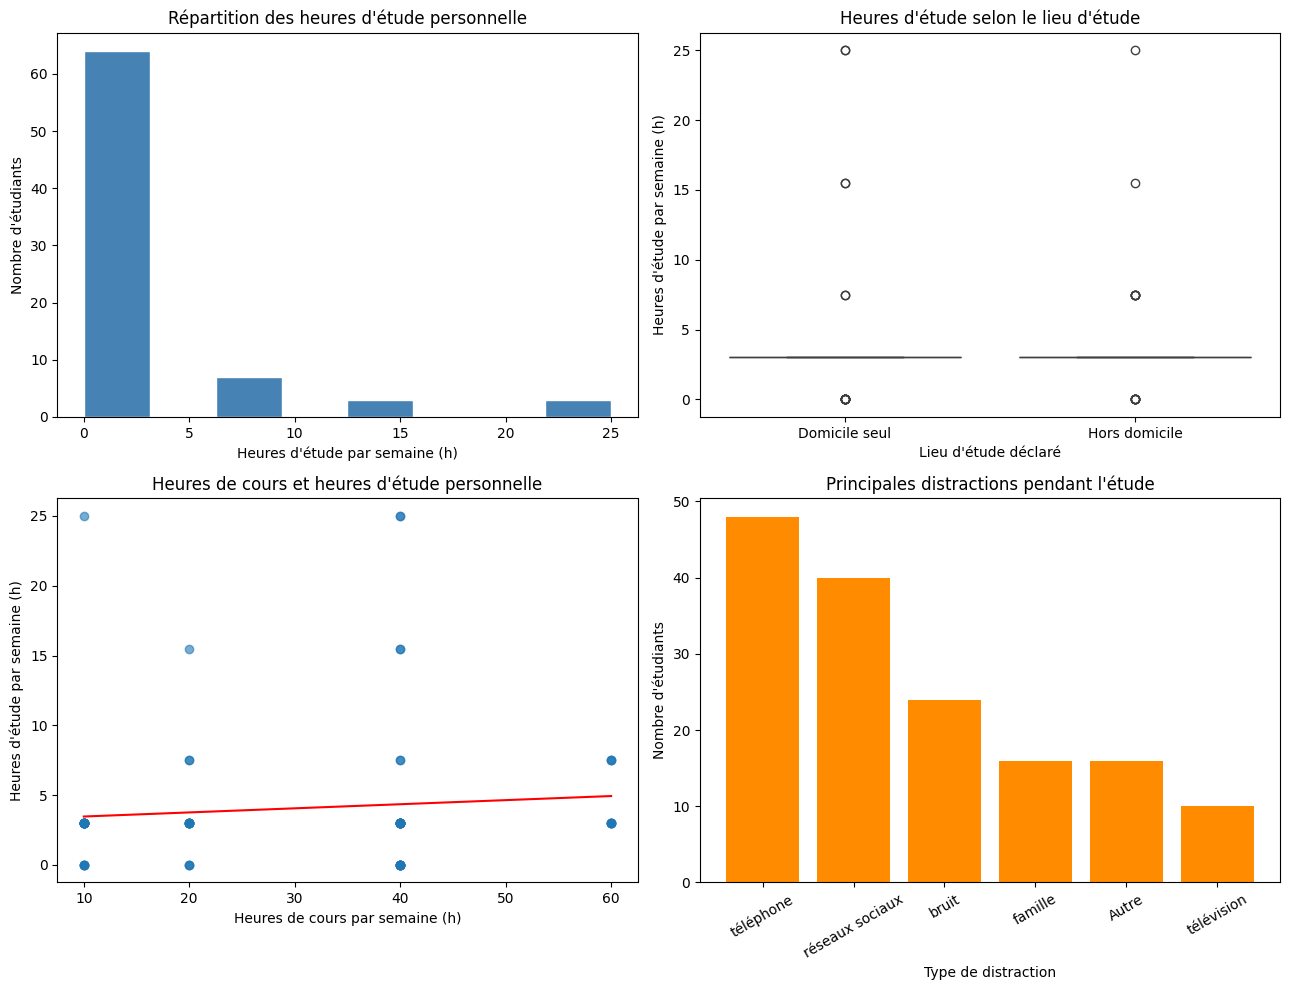

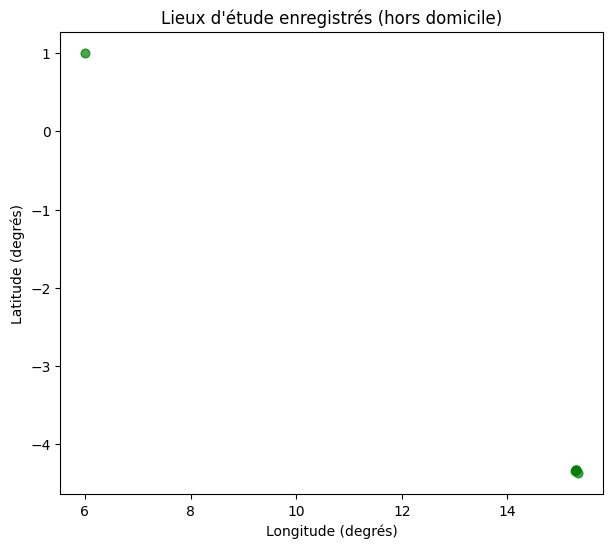

Points GPS affichés : 6


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# 1. Histogramme des heures d'étude
axes[0, 0].hist(data_model["heures_etude_perso"], bins=8, color="steelblue", edgecolor="white")
axes[0, 0].set_title("Répartition des heures d'étude personnelle")
axes[0, 0].set_xlabel("Heures d'étude par semaine (h)")
axes[0, 0].set_ylabel("Nombre d'étudiants")

# 2. Boîte à moustaches : heures d'étude selon le lieu
sns.boxplot(x=data_model["hors_domicile"].map({0: "Domicile seul", 1: "Hors domicile"}),
            y=data_model["heures_etude_perso"], ax=axes[0, 1])
axes[0, 1].set_title("Heures d'étude selon le lieu d'étude")
axes[0, 1].set_xlabel("Lieu d'étude déclaré")
axes[0, 1].set_ylabel("Heures d'étude par semaine (h)")

# 3. Nuage de points heures de cours / heures d'étude avec droite
axes[1, 0].scatter(data_model["heures_cours_sem"], data_model["heures_etude_perso"], alpha=0.6)
pente, ord_orig = np.polyfit(data_model["heures_cours_sem"], data_model["heures_etude_perso"], 1)
xs = np.linspace(data_model["heures_cours_sem"].min(), data_model["heures_cours_sem"].max(), 50)
axes[1, 0].plot(xs, pente * xs + ord_orig, color="red")
axes[1, 0].set_title("Heures de cours et heures d'étude personnelle")
axes[1, 0].set_xlabel("Heures de cours par semaine (h)")
axes[1, 0].set_ylabel("Heures d'étude par semaine (h)")

# 4. Barres des distractions
distr = data[cols_dist].fillna(0).sum().sort_values(ascending=False)
distr.index = [c.split("/")[-1].strip() for c in distr.index]
axes[1, 1].bar(distr.index, distr.values, color="darkorange")
axes[1, 1].set_title("Principales distractions pendant l'étude")
axes[1, 1].set_xlabel("Type de distraction")
axes[1, 1].set_ylabel("Nombre d'étudiants")
axes[1, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# 5. Carte des points GPS (sans les domiciles, déjà retirés)
geo = data[[c_lat, c_lon]].dropna()
plt.figure(figsize=(7, 6))
plt.scatter(geo[c_lon], geo[c_lat], s=40, color="green", alpha=0.7)
plt.title("Lieux d'étude enregistrés (hors domicile)")
plt.xlabel("Longitude (degrés)")
plt.ylabel("Latitude (degrés)")
plt.show()
print(f"Points GPS affichés : {len(geo)}")

# D. OPTIONNEL : matrice de confusion (uniquement si vous prédisez oui/non)


Taux de bonnes réponses : 0.94
Référence (classe majoritaire) : 0.92


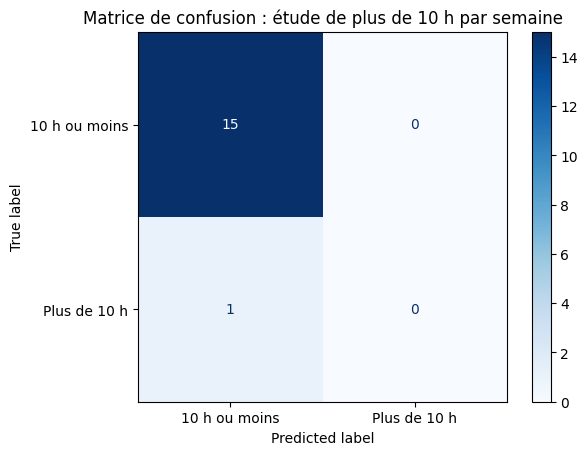

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

X = data_model[features]
y_bin = data_model["etude_plus_10h"]
Xtr, Xte, ytr, yte = train_test_split(X, y_bin, test_size=0.2, random_state=42)

logit = LogisticRegression(max_iter=1000)
logit.fit(Xtr, ytr)
pred = logit.predict(Xte)

print(f"\nTaux de bonnes réponses : {accuracy_score(yte, pred):.2f}")
print(f"Référence (classe majoritaire) : {max(ytr.mean(), 1 - ytr.mean()):.2f}")

ConfusionMatrixDisplay.from_predictions(
    yte, pred, display_labels=["10 h ou moins", "Plus de 10 h"], cmap="Blues")
plt.title("Matrice de confusion : étude de plus de 10 h par semaine")
plt.show()